In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df=pd.read_csv('/content/Feature_selection_2.csv')
df

,Unnamed: 0,FP22,FP80,FP126,FP176,FP198,FP298,FP426,FP437,FP472,...,EStateFP19,EStateFP25,EStateFP28,EStateFP29,EStateFP30,EStateFP32,EStateFP34,EStateFP35,EStateFP36,EStateFP54
0,0,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1,1,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,2,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,3,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,4,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23912,23912,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
23913,23913,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23914,23914,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23915,23915,0,0,0,0,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,0


In [3]:
df = df.drop('Unnamed: 0', axis=1, errors='ignore')

In [4]:
X = df.drop(["class"], axis=1)
Y = df["class"]

In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42)

In [6]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

In [7]:
rf.fit(X_train, Y_train)

RandomForestClassifier(random_state=42)

In [8]:
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

In [9]:
accuracy = accuracy_score(Y_test, y_pred)
auc_score = roc_auc_score(Y_test, y_pred_proba)
clf_report = classification_report(Y_test, y_pred, output_dict=True)

In [25]:
# Confusion Matrix
conf_matrix = confusion_matrix(Y_test, y_pred)
sensitivity = conf_matrix[1, 1] / (conf_matrix[1, 0] + conf_matrix[1, 1])
mae = mean_absolute_error(Y_test, y_pred)
kappa = cohen_kappa_score(Y_test, y_pred)

In [26]:
print("Random Forest Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Classification Report:\n{classification_report(Y_test, y_pred)}")
print("\nConfusion Matrix:")
print(conf_matrix)
print(f"\nSensitivity (Recall): {sensitivity:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Cohen's Kappa Score: {kappa:.4f}")

Random Forest Evaluation Metrics:
Accuracy: 0.9026
AUC: 0.9524
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      4915
           1       0.90      0.77      0.83      2261

    accuracy                           0.90      7176
   macro avg       0.90      0.87      0.88      7176
weighted avg       0.90      0.90      0.90      7176


Confusion Matrix:
[[4725  190]
 [ 509 1752]]

Sensitivity (Recall): 0.7749
Mean Absolute Error (MAE): 0.0974
Cohen's Kappa Score: 0.7654


In [27]:
fpr, tpr, _ = roc_curve(Y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

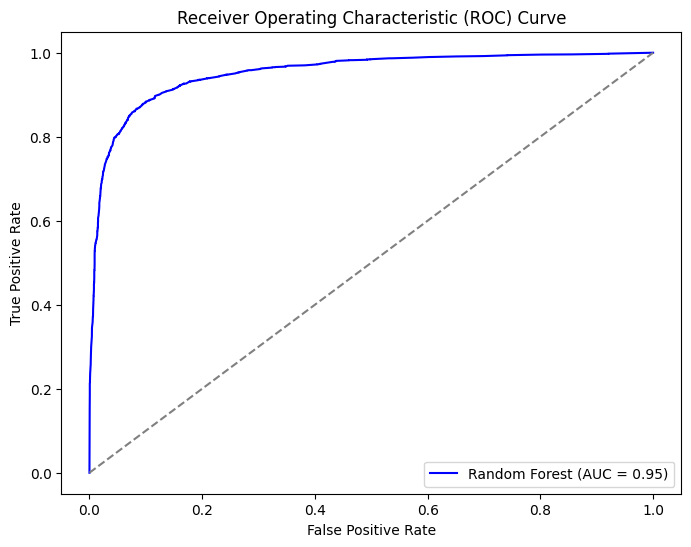

In [28]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')

# ✅ Save the image (added line only)
plt.savefig("roc_curve_random_forest.png", dpi=300, bbox_inches="tight")

plt.show()


In [30]:
# Bar Plot for Sensitivity, MAE, and Kappa Score
metrics = ["Sensitivity (Recall)", "Mean Absolute Error", "Cohen's Kappa Score"]
values = [sensitivity, mae, kappa]

In [32]:
import seaborn as sns

/tmp/ipython-input-3289802166.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette="viridis")


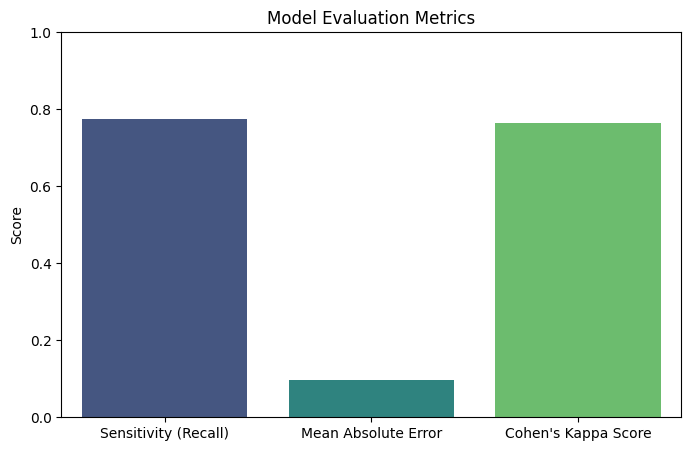

In [33]:
plt.figure(figsize=(8, 5))
sns.barplot(x=metrics, y=values, palette="viridis")
plt.ylabel("Score")
plt.title("Model Evaluation Metrics")
plt.ylim(0, 1)  # Metrics are between 0 and 1

# ✅ Save the image (added line)
plt.savefig("model_evaluation_metrics.png", dpi=300, bbox_inches="tight")

plt.show()
